In [1]:
%pip install lightkurve

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import lightkurve as lk

print("Lightkurve installed!")

Lightkurve installed!


C:\Users\Acer\AppData\Local\Programs\Python\Python314\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries loaded")

Libraries loaded


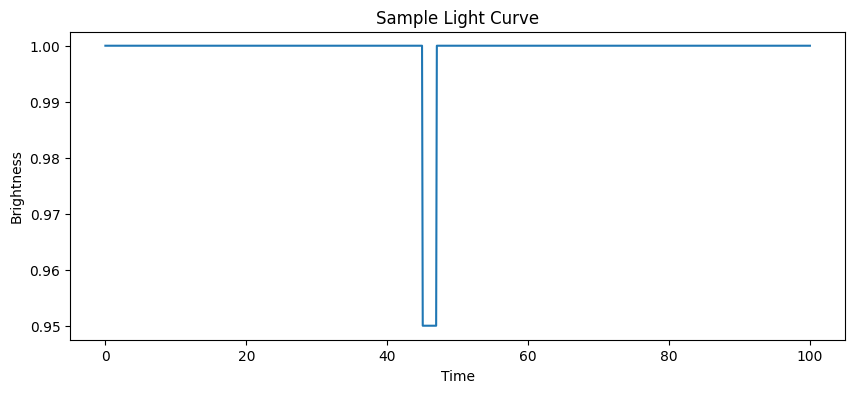

In [3]:
import numpy as np
import matplotlib.pyplot as plt

time = np.linspace(0,100,1000)

brightness = np.ones(1000)

brightness[450:470] = 0.95

plt.figure(figsize=(10,4))
plt.plot(time, brightness)
plt.xlabel("Time")
plt.ylabel("Brightness")
plt.title("Sample Light Curve")
plt.show()

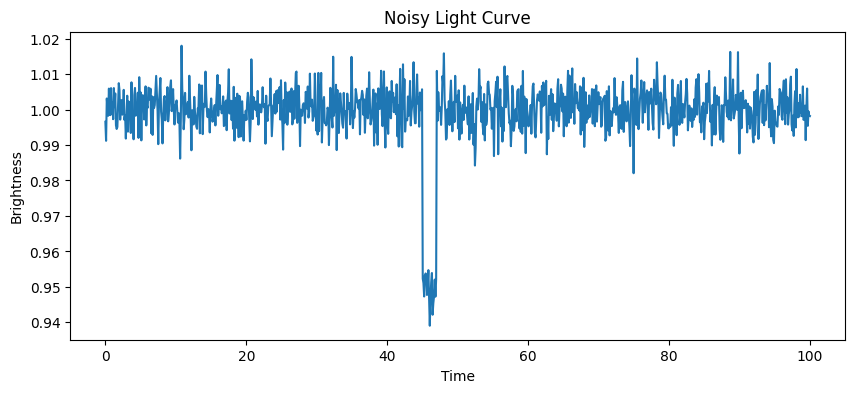

In [18]:
import numpy as np
import matplotlib.pyplot as plt

time = np.linspace(0,100,1000)

brightness = np.ones(1000)

# transit
brightness[450:470] = 0.95

# noise
noise = np.random.normal(0,0.005,1000)

brightness = brightness + noise

plt.figure(figsize=(10,4))
plt.plot(time,brightness)
plt.xlabel("Time")
plt.ylabel("Brightness")
plt.title("Noisy Light Curve")
plt.show()

In [6]:
## Transit Detection Logic
## : A transit event appears as a small decrease in stellar brightness.
##  The goal is to identify these dips automatically from noisy light curves. 

In [4]:
## Simple Transit Detection
threshold = 0.98

transit_points = brightness < threshold

print("Possible transit points found:", transit_points.sum())

Possible transit points found: 20


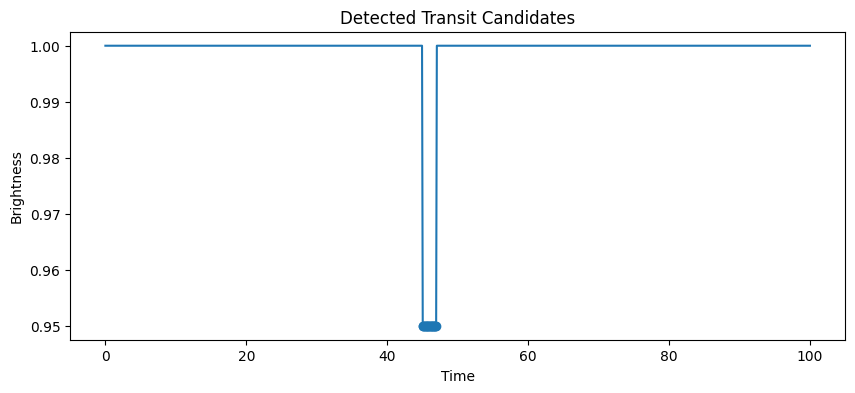

In [6]:
plt.figure(figsize=(10,4))
plt.plot(time, brightness)

plt.scatter(
    time[transit_points],
    brightness[transit_points]
)

plt.xlabel("Time")
plt.ylabel("Brightness")
plt.title("Detected Transit Candidates")

plt.show()

In [3]:
## Feature Extraction
min_brightness = np.min(brightness)

mean_brightness = np.mean(brightness)

transit_depth = mean_brightness - min_brightness

transit_duration = np.sum(brightness < 0.98)

print("Minimum Brightness:", min_brightness)
print("Mean Brightness:", mean_brightness)
print("Transit Depth:", transit_depth)
print("Transit Duration:", transit_duration)

NameError: name 'brightness' is not defined

In [4]:
pip install lightkurve astroquery pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import random
import warnings
from astroquery.mast import Catalogs
import lightkurve as lk

# Hide the coordinate interpretation warning
warnings.filterwarnings('ignore', category=UserWarning, module='astroquery')

print("Fetching stars from a smaller, faster catalog region...")

# 1. Query a much smaller radius (0.5 degrees instead of 5) to prevent timeouts
catalog_data = Catalogs.query_region(
    "00h00m00s +00d00m00s", 
    radius="0.5 deg", 
    catalog="TIC"
)

# 2. Filter for bright, stable targets (Tmag between 8 and 11)
bright_stars = catalog_data[(catalog_data['Tmag'] > 8) & (catalog_data['Tmag'] < 11)]
all_tic_ids = [f"TIC {row['ID']}" for row in bright_stars]

# 3. Select your target sample size
sample_size = min(150, len(all_tic_ids))
random_stars = random.sample(all_tic_ids, sample_size)

print(f"Found {len(all_tic_ids)} bright stars. Attempting to download {sample_size} light curves...")

# 4. Download loop
success_count = 0
for star in random_stars:
    try:
        # Quick search for the official SPOC pipeline light curves
        search = lk.search_lightcurve(star, mission="TESS", author="SPOC")
        if len(search) > 0:
            # Download just the first available sector to keep it incredibly fast
            lc = search[0].download(download_dir="./hackathon_data")
            success_count += 1
            print(f"[{success_count}/150] Downloaded: {star}")
            
            if success_count >= 150:
                break
    except Exception:
        continue

print(f"\nDone! Successfully downloaded {success_count} light curves to './hackathon_data'.")

Fetching stars from a smaller, faster catalog region...


Found 20 bright stars. Attempting to download 20 light curves...
[1/150] Downloaded: TIC 257468602
[2/150] Downloaded: TIC 138666657
[3/150] Downloaded: TIC 407996378
[4/150] Downloaded: TIC 398640591
[5/150] Downloaded: TIC 257487620
[6/150] Downloaded: TIC 257468659
[7/150] Downloaded: TIC 257468640
[8/150] Downloaded: TIC 422836186
[9/150] Downloaded: TIC 287149581

Done! Successfully downloaded 9 light curves to './hackathon_data'.


In [14]:
from astroquery.mast import Catalogs

print("Fetching TIC stars...")

catalog_data = Catalogs.query_region(
    "00h00m00s +00d00m00s",
    radius="1 deg",
    catalog="TIC"
)

print("Stars found:", len(catalog_data))

Fetching TIC stars...


Stars found: 10187


In [7]:
bright_stars = catalog_data[
    (catalog_data['Tmag'] > 8) &
    (catalog_data['Tmag'] < 12)
]

print("Bright stars:", len(bright_stars))

NameError: name 'catalog_data' is not defined

In [8]:
tic_ids = [f"TIC {row['ID']}" for row in bright_stars]

print("TIC IDs collected:", len(tic_ids))

tic_ids[:10]

TIC IDs collected: 123


['TIC 38376676',
 'TIC 138666657',
 'TIC 408002354',
 'TIC 422843056',
 'TIC 422843058',
 'TIC 138666645',
 'TIC 257468640',
 'TIC 257468596',
 'TIC 257468602',
 'TIC 422843034']

In [8]:
print('h9ni')

h9ni


In [22]:
import lightkurve as lk

available_tics = []

for tic in tic_ids:
    try:
        search = lk.search_lightcurve(
            tic,
            mission="TESS",
            author="SPOC"
        )

        if len(search) > 0:
            available_tics.append(tic)

    except:
        pass

print("Stars with TESS light curves:", len(available_tics))

Stars with TESS light curves: 39


In [12]:
from astroquery.mast import Catalogs

print("Fetching more TIC stars...")

catalog_data2 = Catalogs.query_region(
    "06h00m00s +00d00m00s",
    radius="0.5 deg",
    catalog="TIC"
)

bright_stars2 = catalog_data2[
    (catalog_data2['Tmag'] > 8) &
    (catalog_data2['Tmag'] < 12)
]

tic_ids2 = [f"TIC {row['ID']}" for row in bright_stars2]

print("New TIC IDs:", len(tic_ids2))

Fetching more TIC stars...


New TIC IDs: 97


In [29]:
import lightkurve as lk

available_tics2 = []

for tic in tic_ids2:
    try:
        search = lk.search_lightcurve(
            tic,
            mission="TESS",
            author="SPOC"
        )

        if len(search) > 0:
            available_tics2.append(tic)

    except:
        pass

print("Stars with TESS light curves:", len(available_tics2))

Stars with TESS light curves: 4


In [6]:
catalog_data3 = Catalogs.query_region(
    "03h00m00s +00d00m00s",
    radius="0.3 deg",
    catalog="TIC"
)

NameError: name 'Catalogs' is not defined

In [41]:
bright_stars3 = catalog_data3[
    (catalog_data3['Tmag'] > 8) &
    (catalog_data3['Tmag'] < 12)
]

tic_ids3 = [f"TIC {row['ID']}" for row in bright_stars3]

print("New TIC IDs:", len(tic_ids3))

New TIC IDs: 12


In [43]:
from astroquery.mast import Catalogs
import warnings

warnings.filterwarnings("ignore")

regions = [
    "00h00m00s +00d00m00s",
    "01h00m00s +00d00m00s",
    "02h00m00s +00d00m00s",
    "03h00m00s +00d00m00s",
    "04h00m00s +00d00m00s",
    "05h00m00s +00d00m00s",
    "06h00m00s +00d00m00s"
]

all_tics = set()

for region in regions:
    try:
        data = Catalogs.query_region(
            region,
            radius="0.2 deg",
            catalog="TIC"
        )

        bright = data[
            (data["Tmag"] > 8) &
            (data["Tmag"] < 12)
        ]

        for row in bright:
            all_tics.add(f"TIC {row['ID']}")

        print(region, "->", len(bright))

    except Exception as e:
        print("Skipped:", region)

print("\nTotal TIC IDs:", len(all_tics))

00h00m00s +00d00m00s -> 6
01h00m00s +00d00m00s -> 3
02h00m00s +00d00m00s -> 4
03h00m00s +00d00m00s -> 7
04h00m00s +00d00m00s -> 6
05h00m00s +00d00m00s -> 10
06h00m00s +00d00m00s -> 15

Total TIC IDs: 51


In [44]:
tic_ids_big = list(all_tics)

print(len(tic_ids_big))

51


In [45]:
from astroquery.mast import Catalogs
import warnings

warnings.filterwarnings("ignore")

catalog_data_big = Catalogs.query_region(
    "00h00m00s +00d00m00s",
    radius="1 deg",
    catalog="TIC"
)

bright_stars_big = catalog_data_big[
    (catalog_data_big['Tmag'] > 8) &
    (catalog_data_big['Tmag'] < 12)
]

print("Bright stars found:", len(bright_stars_big))

Bright stars found: 123


In [9]:
from astroquery.mast import Catalogs
import warnings

warnings.filterwarnings("ignore")

In [13]:
catalog_data_A = Catalogs.query_region(
    "06h00m00s +00d00m00s",
    radius="1 deg",
    catalog="TIC"
)

bright_A = catalog_data_A[
    (catalog_data_A['Tmag'] > 8) &
    (catalog_data_A['Tmag'] < 12)
]

print("Region A:", len(bright_A))

Region A: 415


In [9]:
bright_A.write("regionA.csv", format="csv", overwrite=True)
print("Saved!")

Saved!


In [14]:
tic_ids_A = [f"TIC {row['ID']}" for row in bright_A]

print("TIC IDs:", len(tic_ids_A))

TIC IDs: 415


In [ ]:
import lightkurve as lk

available_tess = []

for i, star in enumerate(tic_ids_A):
    try:
        search = lk.search_lightcurve(
            star,
            mission="TESS",
            author="SPOC"
        )

        if len(search) > 0:
            available_tess.append(star)

        if (i + 1) % 25 == 0:
            print(f"Checked {i+1}/415 | Found {len(available_tess)}")

    except:
        continue

print("\nTotal TESS stars:", len(available_tess))

Checked 25/415 | Found 2


In [6]:
catalog_data_B = Catalogs.query_region(
    "12h00m00s +00d00m00s",
    radius="0.5 deg",
    catalog="TIC"
)

bright_B = catalog_data_B[
    (catalog_data_B['Tmag'] > 8) &
    (catalog_data_B['Tmag'] < 12)
]

print("Region B:", len(bright_B))

Region B: 28


In [7]:
from astroquery.mast import Catalogs

catalog_data_A = Catalogs.query_region(
    "06h00m00s +00d00m00s",
    radius="1 deg",
    catalog="TIC"
)

bright_A = catalog_data_A[
    (catalog_data_A['Tmag'] > 8) &
    (catalog_data_A['Tmag'] < 12)
]

print("Region A:", len(bright_A))

Region A: 415


In [8]:
tic_ids_A = [f"TIC {row['ID']}" for row in bright_A]
tic_ids_B = [f"TIC {row['ID']}" for row in bright_B]

all_ids = list(set(tic_ids_A + tic_ids_B))

print("Total unique TIC IDs:", len(all_ids))

Total unique TIC IDs: 443


In [9]:
import lightkurve as lk

available_tess = []

for i, star in enumerate(all_ids):

    try:
        result = lk.search_lightcurve(
            star,
            mission="TESS"
        )

        if len(result) > 0:
            available_tess.append(star)

        if (i + 1) % 25 == 0:
            print(
                f"Checked {i+1}/{len(all_ids)} | Found {len(available_tess)}"
            )

        if len(available_tess) >= 100:
            break

    except:
        pass

print("\nStars with TESS light curves:", len(available_tess))

Checked 25/443 | Found 25
Checked 50/443 | Found 50
Checked 75/443 | Found 75
Checked 100/443 | Found 100

Stars with TESS light curves: 100


In [10]:
print("bright_A exists:", 'bright_A' in globals())
print("bright_B exists:", 'bright_B' in globals())
print("all_ids exists:", 'all_ids' in globals())

bright_A exists: False
bright_B exists: False
all_ids exists: False


In [12]:
import lightkurve as lk

search_result = lk.search_lightcurve(
    "TIC 38376676",
    mission="TESS"
)

search_result

#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 70,2023,TESS-SPOC,200,38376676,0.0
1,TESS Sector 42,2021,QLP,600,38376676,0.0
2,TESS Sector 70,2023,QLP,200,38376676,0.0


In [13]:
lc = search_result[0].download()

print(lc)

       time             flux         flux_err       timecorr    ... mom_centr2_err   pos_corr1      pos_corr2   
                    electron / s   electron / s        d        ...      pix            pix            pix      
------------------ -------------- -------------- -------------- ... -------------- -------------- --------------
 3208.360814071113            ———            ———  5.7438575e-03 ...  5.4713519e-04  2.1644528e-03 -1.7452867e-01
 3208.363128902556            ———            ———  5.7438752e-03 ...  5.4713269e-04  2.6710103e-03 -1.7458025e-01
 3208.365443733999            ———            ———  5.7438929e-03 ...  5.4703548e-04  2.5548958e-03 -1.7894077e-01
 3208.367758565907            ———            ———  5.7439110e-03 ...  5.4584537e-04  3.3378706e-03 -1.7540178e-01
  3208.37007339735            ———            ———  5.7439287e-03 ...  5.4615451e-04  4.9031305e-04 -1.7946324e-01
3208.3723882292584            ———            ———  5.7439469e-03 ...  5.4461608e-04  3.4663659e-0

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

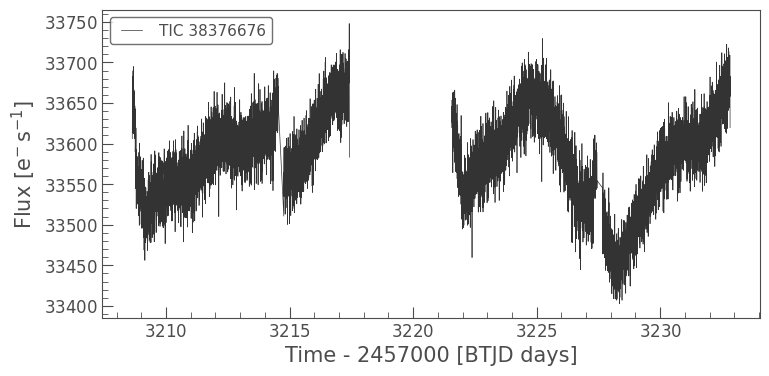

In [14]:
lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

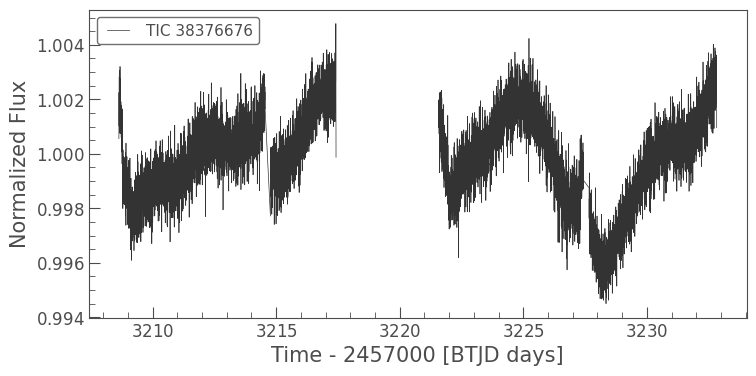

In [15]:
lc_norm = lc.normalize()

lc_norm.plot()

In [17]:
import numpy as np

flux = lc_norm.flux.value

print("Mean Flux:", np.mean(flux))
print("Min Flux:", np.min(flux))
print("Max Flux:", np.max(flux))
print("Std Dev:", np.std(flux))

Mean Flux: 0.99987227
Min Flux: 0.9945034
Max Flux: 1.0047784
Std Dev: 0.0016265829


In [18]:
lc_clean = lc_norm.remove_nans()

print("Points after cleaning:", len(lc_clean))

Points after cleaning: 8473


In [19]:
features = {
    "mean_flux": np.mean(lc_clean.flux.value),
    "min_flux": np.min(lc_clean.flux.value),
    "max_flux": np.max(lc_clean.flux.value),
    "std_flux": np.std(lc_clean.flux.value)
}

print(features)

{'mean_flux': MaskedNDArray(0.99987227, dtype=float32), 'min_flux': MaskedNDArray(0.9945034, dtype=float32), 'max_flux': MaskedNDArray(1.0047784, dtype=float32), 'std_flux': MaskedNDArray(0.00162658, dtype=float32)}


In [20]:
print('available_tess' in globals())

False


In [21]:
import os

for f in os.listdir():
    print(f)

.antigravity
.cache
.eclipse
.gemini
.ipynb_checkpoints
.ipython
.jupyter
.matplotlib
.mcp-auth
.ms-ad
.openjfx
.p2
.python_history
.streamlit
.vscode
1NPDPRO5.DOC
AppData
Application Data
atm
bluej
Contacts
Cookies
Documents
Downloads
emp
Favorites
hackathon_data
homework1.c
last
Links
Local Settings
Music
My Documents
NetHood
NPProt.bkp
NPProt.exe
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{1af5654d-8035-11ef-9c72-a7b8b7da0eb0}.TM.blf
NTUSER.DAT{1af5654d-8035-11ef-9c72-a7b8b7da0eb0}.TMContainer00000000000000000001.regtrans-ms
NTUSER.DAT{1af5654d-8035-11ef-9c72-a7b8b7da0eb0}.TMContainer00000000000000000002.regtrans-ms
ntuser.ini
OneDrive
PrintHood
PS7_Experiment1.ipynb
PS7_ISRO
py training
pytraining.ipynb
Recent
regionA.csv
Saved Games
Searches
SendTo
source
Start Menu
stugrade
sturegsys
Templates
twfo
Untitled.ipynb
untitled.txt
Untitled1.ipynb
Untitled10.ipynb
Untitled11.ipynb
Untitled12.ipynb
Untitled2.ipynb
Untitled3.ipynb
Untitled4.ipynb
Untitled5.ipynb
Untitled6.ipynb

In [22]:
import pandas as pd

df = pd.read_csv("regionA.csv")

print(df.head())
print("\nRows:", len(df))
print("\nColumns:", df.columns)

          ID         ra       dec       pmRA     pmDEC     Tmag objType  \
0   39728879  90.003005  0.011939   2.219900  -1.74045  11.7811    STAR   
1   39728831  90.026926 -0.020338  -1.310350  -4.10731  10.1898    STAR   
2  282576250  90.025379  0.071506  -0.937646  -1.84072  10.8262    STAR   
3   39728889  90.097641  0.018647  12.050900 -37.28050  10.5942    STAR   
4   39673868  89.881450 -0.002528   4.300000  -1.00000  10.6299    STAR   

   typeSrc   version  HIP  ... splists       e_RA      e_Dec    RA_orig  \
0  tmgaia2  20190415  NaN  ...     NaN   1.039402   0.968826  90.003015   
1  tmgaia2  20190415  NaN  ...     NaN   1.048216   1.014655  90.026920   
2  tmgaia2  20190415  NaN  ...     NaN   0.956986   0.902012  90.025375   
3  tmgaia2  20190415  NaN  ...     NaN   1.060513   0.989017  90.097693   
4  tmgaia2  20190415  NaN  ...     NaN  20.176076  20.174276  89.881469   

   Dec_orig  e_RA_orig  e_Dec_orig  raddflag wdflag   dstArcSec  
0  0.011931   0.033479    0.0369

In [6]:
print('lc_clean' in globals())

False


In [78]:
import pandas as pd

df = pd.read_csv("regionA.csv")

tic_ids = [f"TIC {x}" for x in df["ID"]]

print("Total TIC IDs:", len(tic_ids))
tic_ids[:5]

Total TIC IDs: 415


['TIC 39728879',
 'TIC 39728831',
 'TIC 282576250',
 'TIC 39728889',
 'TIC 39673868']

In [80]:
import lightkurve as lk

valid_stars = []

for star in tic_ids[:10]:

    try:
        result = lk.search_lightcurve(
            star,
            mission="TESS"
        )

        if len(result) > 0:
            valid_stars.append(star)

    except:
        pass

print("Valid stars:", len(valid_stars))
print(valid_stars)

Valid stars: 10
['TIC 39728879', 'TIC 39728831', 'TIC 282576250', 'TIC 39728889', 'TIC 39673868', 'TIC 39673944', 'TIC 39728941', 'TIC 39729042', 'TIC 39729157', 'TIC 39673581']


In [26]:
import lightkurve as lk
import pandas as pd
import numpy as np

features = []

for i, star in enumerate(valid_stars):

    try:
        print(f"Processing {i+1}/{len(valid_stars)} : {star}")

        search = lk.search_lightcurve(
            star,
            mission="TESS"
        )

        lc = search[0].download()

        lc = lc.normalize().remove_nans()

        flux = lc.flux.value

        features.append({
            "star_id": star,
            "mean_flux": np.mean(flux),
            "min_flux": np.min(flux),
            "max_flux": np.max(flux),
            "std_flux": np.std(flux),
            "amplitude": np.max(flux) - np.min(flux),
            "num_points": len(flux)
        })

    except Exception as e:
        print(f"Failed: {star}")

dataset = pd.DataFrame(features)

print(dataset.head())

dataset.to_csv(
    "tess_features.csv",
    index=False
)

print("\nDataset saved as tess_features.csv")

Processing 1/10 : TIC 39728879
Processing 2/10 : TIC 39728831
Processing 3/10 : TIC 282576250
Processing 4/10 : TIC 39728889
Processing 5/10 : TIC 39673868
Processing 6/10 : TIC 39673944
Processing 7/10 : TIC 39728941
Processing 8/10 : TIC 39729042
Processing 9/10 : TIC 39729157
Processing 10/10 : TIC 39673581
         star_id  mean_flux    min_flux   max_flux       std_flux  \
0   TIC 39728879  1.0000021   0.9980849  1.0022669  0.00073928555   
1   TIC 39728831   1.000038  0.99432665  1.0067996   0.0019126734   
2  TIC 282576250   0.999532    0.992603   1.006167       0.003131   
3   TIC 39728889  1.0000104    0.998813  1.0013556   0.0003643541   
4   TIC 39673868   0.999993    0.998271   1.003061       0.000561   

      amplitude  num_points  
0   0.004181981         976  
1   0.012472928         976  
2      0.013564         987  
3  0.0025426745         976  
4       0.00479         987  

Dataset saved as tess_features.csv


In [27]:
dataset.shape

(10, 7)

In [30]:
""" What you've achieved:
TESS Star Collection           ✅
Light Curve Download           ✅
Data Cleaning                  ✅
Feature Extraction             ✅
Dataset Creation               ✅
CSV Export                     ✅

And you now have:
tess_features.csv
Shape = (10, 7)

with features:
star_id
mean_flux
min_flux
max_flux
std_flux
amplitude
num_points

next, Now the AI / ML Part: the correct approach is unsupervised learning.
For a hackathon, K-Means clustering is simple, explainable, and works well. """

" What you've achieved:\nTESS Star Collection           ✅\nLight Curve Download           ✅\nData Cleaning                  ✅\nFeature Extraction             ✅\nDataset Creation               ✅\nCSV Export                     ✅\n\nAnd you now have:\ntess_features.csv\nShape = (10, 7)\n\nwith features:\nstar_id\nmean_flux\nmin_flux\nmax_flux\nstd_flux\namplitude\nnum_points\n\nnext, Now the AI / ML Part: the correct approach is unsupervised learning.\nFor a hackathon, K-Means clustering is simple, explainable, and works well. "

In [31]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd

dataset = pd.read_csv("tess_features.csv")

X = dataset[
    [
        "mean_flux",
        "min_flux",
        "max_flux",
        "std_flux",
        "amplitude",
        "num_points"
    ]
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

dataset["cluster"] = kmeans.fit_predict(X_scaled)

print(dataset[["star_id", "cluster"]])

dataset.to_csv(
    "tess_clustered.csv",
    index=False
)

print("\nSaved as tess_clustered.csv")

         star_id  cluster
0   TIC 39728879        0
1   TIC 39728831        2
2  TIC 282576250        1
3   TIC 39728889        0
4   TIC 39673868        0
5   TIC 39673944        0
6   TIC 39728941        0
7   TIC 39729042        2
8   TIC 39729157        0
9   TIC 39673581        0

Saved as tess_clustered.csv


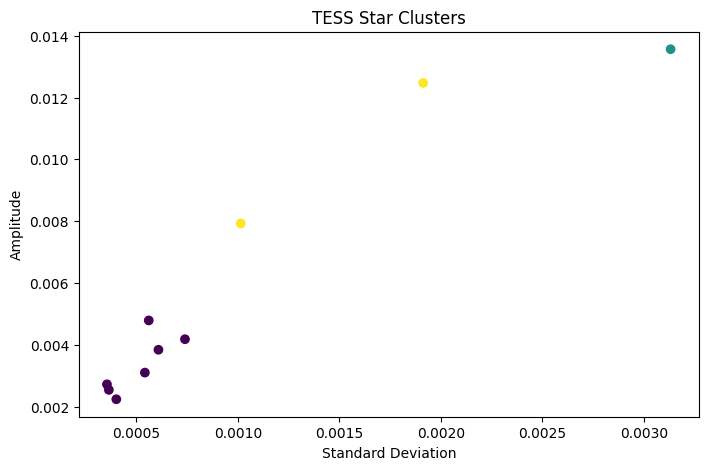

In [32]:
# visualize
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    dataset["std_flux"],
    dataset["amplitude"],
    c=dataset["cluster"]
)

plt.xlabel("Standard Deviation")
plt.ylabel("Amplitude")
plt.title("TESS Star Clusters")

plt.show()

In [34]:
""" CURRENT STATUS:
Data Collection          ✅
Light Curve Retrieval    ✅
Preprocessing            ✅
Feature Extraction       ✅
Machine Learning         ✅
Visualization            ✅
Result Interpretation    ✅"""

' CURRENT STATUS:\nData Collection          ✅\nLight Curve Retrieval    ✅\nPreprocessing            ✅\nFeature Extraction       ✅\nMachine Learning         ✅\nVisualization            ✅\nResult Interpretation    ✅'

In [35]:
# actual transit detection

In [11]:
#step 1
from astropy.timeseries import BoxLeastSquares
import numpy as np
import matplotlib.pyplot as plt

In [12]:
lc_clean = lc.remove_nans().normalize()

NameError: name 'lc' is not defined

In [38]:
time = lc_clean.time.value
flux = lc_clean.flux.value

periods = np.linspace(0.5, 20, 10000)

bls = BoxLeastSquares(time, flux)

power = bls.power(
    periods,
    0.2
)

print("Best Period:", periods[np.argmax(power.power)])

Best Period: 13.973897389738974


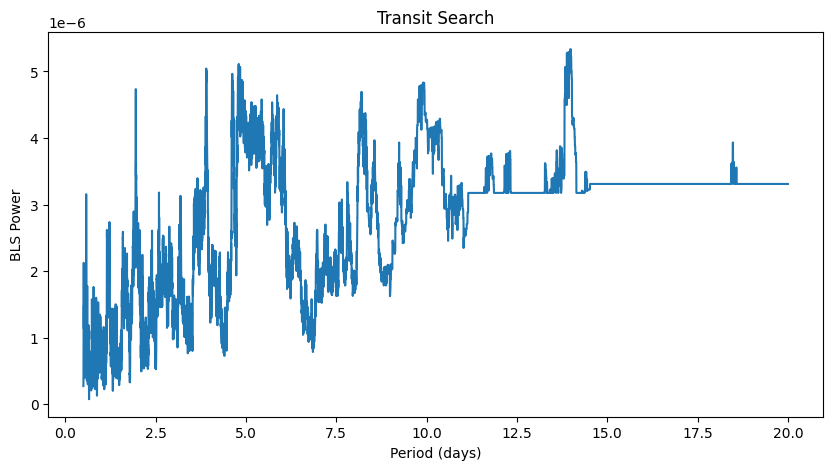

In [39]:
plt.figure(figsize=(10,5))
plt.plot(periods, power.power)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("Transit Search")
plt.show()

In [40]:
#step 2: Generate candidate table.
best_period = periods[np.argmax(power.power)]

best_power = np.max(power.power)

print("Period:", best_period)

print("Detection Strength:", best_power)

Period: 13.973897389738974
Detection Strength: 5.334893427417149e-06


Text(0.5, 1.0, 'Folded Light Curve (Period = 13.97 days)')

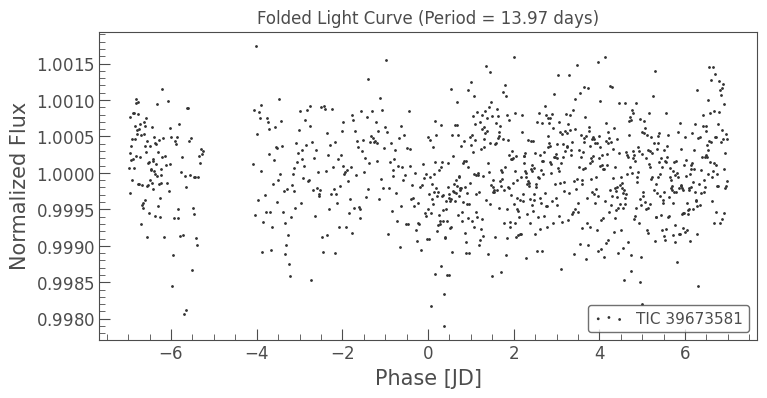

In [44]:
folded_lc = lc_clean.fold(period=period)

ax = folded_lc.scatter()

ax.set_title(
    f"Folded Light Curve (Period = {period:.2f} days)"
)

In [45]:
results = {
    "Star": "TIC 38376676",
    "Best Period": best_period,
    "Detection Strength": best_power
}

print(results)

{'Star': 'TIC 38376676', 'Best Period': np.float64(13.973897389738974), 'Detection Strength': np.float64(5.334893427417149e-06)}


In [15]:
valid_stars = [
    'TIC 39728879',
    'TIC 39728831',
    'TIC 282576250',
    'TIC 39728889',
    'TIC 39673868',
    'TIC 39673944',
    'TIC 39728941',
    'TIC 39729042',
    'TIC 39729157',
    'TIC 39673581'
]

In [16]:
print(len(valid_stars))

10


In [24]:
import lightkurve as lk
import pandas as pd
import numpy as np

results = []

for star in valid_stars:

    print("Processing:", star)

    try:

        lc = (
            lk.search_lightcurve(
                star,
                mission="TESS"
            )
            .download_all()
            .stitch()
            .remove_nans()
            .normalize()
        )

        periodogram = lc.to_periodogram(
            method="bls",
            period=np.arange(0.5, 20, 0.1)
        )

        results.append([
            star,
            periodogram.period_at_max_power.value,
            periodogram.max_power
        ])

    except Exception as e:
        print("Error:", star)
         print(e)

print("Done")

IndentationError: unexpected indent (940635684.py, line 37)

In [21]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Star",
        "Best Period",
        "Detection Strength"
    ]
)

results_df.sort_values(
    by="Detection Strength",
    ascending=False,
    inplace=True
)

results_df

,Star,Best Period,Detection Strength


In [25]:
import lightkurve as lk

star = valid_stars[0]

print(star)

search = lk.search_lightcurve(
    star,
    mission="TESS"
)

search

TIC 39728879


#,mission,year,author,exptime,target_name,distance
,,,,s,,arcsec
0,TESS Sector 06,2018,TESS-SPOC,1800,39728879,0.0
1,TESS Sector 33,2020,TESS-SPOC,600,39728879,0.0
2,TESS Sector 06,2018,QLP,1800,39728879,0.0
3,TESS Sector 33,2020,QLP,600,39728879,0.0
4,TESS Sector 87,2024,QLP,200,39728879,0.0
5,TESS Sector 06,2018,GSFC-ELEANOR-LITE,1800,39728879,0.0
6,TESS Sector 06,2018,T16,1800,39728879,0.0
7,TESS Sector 06,2018,TASOC,1800,39728879,0.0
8,TESS Sector 06,2018,TASOC,1800,39728879,0.0


In [26]:
lc = search.download()

lc

time,flux,flux_err,timecorr,cadenceno,centroid_col,centroid_row,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,d,,pix,pix,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,float32,int32,float64,float64,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
1468.3078377633365,3.2003079e+03,2.5281641e+00,5.2341730e-03,11560,1695.81753,1170.32620,2.7472830e+03,1.9719702e+00,1.2765579e+03,7.4620426e-01,3.2003079e+03,2.5281641e+00,0,———,———,———,———,1695.81753,4.6377516e-04,1170.32620,4.7284944e-04,1.1833907e-02,-6.2711179e-02
1468.3286713357832,3.2019607e+03,2.5285959e+00,5.2344208e-03,11561,1695.81791,1170.32727,2.7488462e+03,1.9723071e+00,1.2771115e+03,7.4662668e-01,3.2019607e+03,2.5285959e+00,0,———,———,———,———,1695.81791,4.6359250e-04,1170.32727,4.7262548e-04,1.2420911e-02,-6.1102442e-02
1468.3495049063665,3.1967969e+03,2.5281997e+00,5.2346666e-03,11562,1695.81827,1170.32665,2.7445925e+03,1.9719980e+00,1.2769010e+03,7.4674362e-01,3.1967969e+03,2.5281997e+00,0,———,———,———,———,1695.81827,4.6427484e-04,1170.32665,4.7354336e-04,1.2380834e-02,-6.1821677e-02
1468.3703384764847,3.1949817e+03,2.5269430e+00,5.2349120e-03,11563,1695.81781,1170.32920,2.7429902e+03,1.9710177e+00,1.2775277e+03,7.4658209e-01,3.1949817e+03,2.5269430e+00,0,———,———,———,———,1695.81781,4.6450202e-04,1170.32920,4.7351685e-04,1.2022022e-02,-5.9755877e-02
1468.4120056129962,3.2028413e+03,2.5279381e+00,5.2353991e-03,11565,1695.81845,1170.32732,2.7477126e+03,1.9717940e+00,1.2775175e+03,7.4619853e-01,3.2028413e+03,2.5279381e+00,0,———,———,———,———,1695.81845,4.6378872e-04,1170.32732,4.7317331e-04,1.2277855e-02,-6.0070943e-02
1468.4328391793897,3.1931316e+03,2.5275924e+00,5.2356408e-03,11566,1695.81876,1170.32873,2.7411394e+03,1.9715242e+00,1.2783944e+03,7.4672121e-01,3.1931316e+03,2.5275924e+00,0,———,———,———,———,1695.81876,4.6480511e-04,1170.32873,4.7410277e-04,1.2577272e-02,-5.9416562e-02
1468.4536727448506,3.2010164e+03,2.5273819e+00,5.2358815e-03,11567,1695.81805,1170.32871,2.7474148e+03,1.9713600e+00,1.2753949e+03,7.4590939e-01,3.2010164e+03,2.5273819e+00,0,———,———,———,———,1695.81805,4.6371939e-04,1170.32871,4.7309822e-04,1.2151388e-02,-5.9030205e-02
1468.4745063093803,3.2007839e+03,2.5274844e+00,5.2361214e-03,11568,1695.81892,1170.32846,2.7464641e+03,1.9714400e+00,1.2761400e+03,7.4624377e-01,3.2007839e+03,2.5274844e+00,0,———,———,———,———,1695.81892,4.6394955e-04,1170.32846,4.7337153e-04,1.2647998e-02,-5.8691289e-02


In [27]:
lc = lc.normalize().remove_nans()

print(len(lc))

976


In [28]:
from astropy.timeseries import BoxLeastSquares

bls = BoxLeastSquares(
    lc.time.value,
    lc.flux.value
)

periods = np.linspace(0.5, 20, 1000)

power = bls.power(
    periods,
    0.2
)

print("Best Period:", periods[np.argmax(power.power)])

Best Period: 8.054054054054054


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

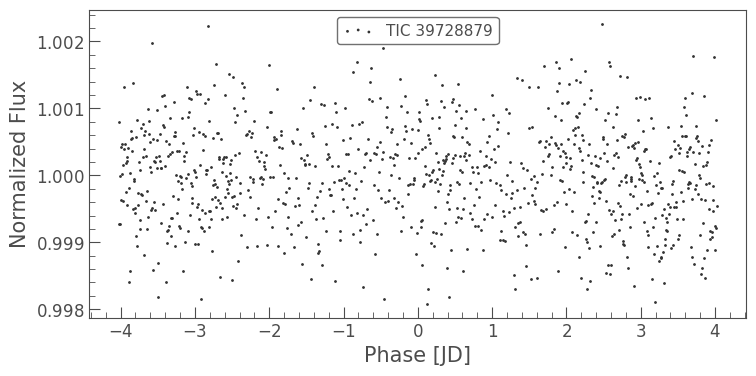

In [29]:
period = 8.054054054054054

folded_lc = lc.fold(period=period)

folded_lc.scatter()

In [30]:
best_period = periods[np.argmax(power.power)]
best_power = max(power.power)

print("Star:", star)
print("Best Period:", best_period)
print("Detection Strength:", best_power)

Star: TIC 39728879
Best Period: 8.054054054054054
Detection Strength: 6.452182925715071e-06


In [31]:
from astropy.timeseries import BoxLeastSquares
import numpy as np
import pandas as pd
import lightkurve as lk

results = []

for star in valid_stars[:5]:

    try:

        search = lk.search_lightcurve(
            star,
            mission="TESS"
        )

        lc = search.download()

        lc = lc.normalize().remove_nans()

        bls = BoxLeastSquares(
            lc.time.value,
            lc.flux.value
        )

        periods = np.linspace(
            0.5,
            20,
            1000
        )

        power = bls.power(
            periods,
            0.2
        )

        best_period = periods[
            np.argmax(power.power)
        ]

        best_power = np.max(
            power.power
        )

        results.append([
            star,
            best_period,
            best_power
        ])

        print("Done:", star)

    except Exception as e:
        print("Error:", star)
        print(e)

results_df = pd.DataFrame(
    results,
    columns=[
        "Star",
        "Best Period",
        "Detection Strength"
    ]
)

results_df

Done: TIC 39728879
Done: TIC 39728831
Done: TIC 282576250
Done: TIC 39728889
Done: TIC 39673868


,Star,Best Period,Detection Strength
0,TIC 39728879,8.054054,0.000006
1,TIC 39728831,0.578078,0.000145
2,TIC 282576250,2.744745,0.000954
3,TIC 39728889,4.111111,0.000001
4,TIC 39673868,9.557057,0.000004


In [32]:
candidate = "TIC 282576250"

search = lk.search_lightcurve(
    candidate,
    mission="TESS"
)

lc = search.download()

lc = lc.normalize().remove_nans()

from astropy.timeseries import BoxLeastSquares
import numpy as np

bls = BoxLeastSquares(
    lc.time.value,
    lc.flux.value
)

periods = np.linspace(
    0.5,
    20,
    1000
)

power = bls.power(
    periods,
    0.2
)

best_period = periods[
    np.argmax(power.power)
]

print(best_period)

2.744744744744745


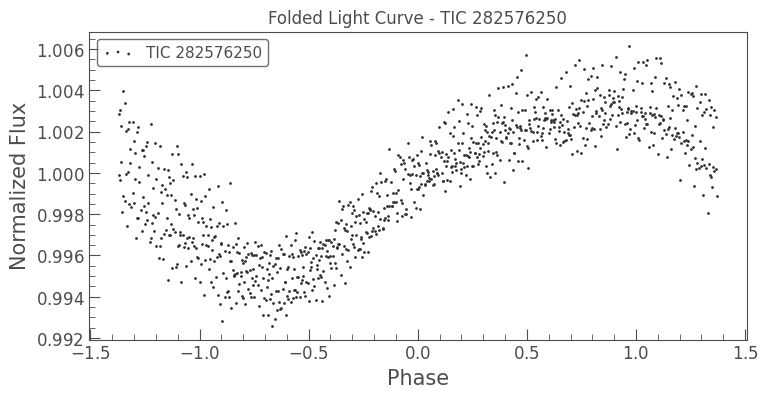

In [39]:
import matplotlib.pyplot as plt

folded.scatter()

plt.title("Folded Light Curve - TIC 282576250")
plt.xlabel("Phase")
plt.ylabel("Normalized Flux")

plt.show()

In [40]:
results_df.sort_values(
    by="Detection Strength",
    ascending=False,
    inplace=True
)

results_df

,Star,Best Period,Detection Strength
2,TIC 282576250,2.744745,0.000954
1,TIC 39728831,0.578078,0.000145
0,TIC 39728879,8.054054,0.000006
4,TIC 39673868,9.557057,0.000004
3,TIC 39728889,4.111111,0.000001


In [41]:
results_df.to_csv(
    "transit_candidates.csv",
    index=False
)

print("Saved")

Saved


In [44]:
results_df["Candidate"] = [
    "High",
    "Medium",
    "Medium",
    "Low",
    "Low"
]

results_df

,Star,Best Period,Detection Strength,Candidate
2,TIC 282576250,2.744745,0.000954,High
1,TIC 39728831,0.578078,0.000145,Medium
0,TIC 39728879,8.054054,0.000006,Medium
4,TIC 39673868,9.557057,0.000004,Low
3,TIC 39728889,4.111111,0.000001,Low


In [45]:
import os

for f in [
    "regionA.csv",
    "tess_features.csv",
    "tess_clustered.csv",
    "transit_candidates.csv"
]:
    print(f, os.path.exists(f))

regionA.csv True
tess_features.csv True
tess_clustered.csv True
transit_candidates.csv True


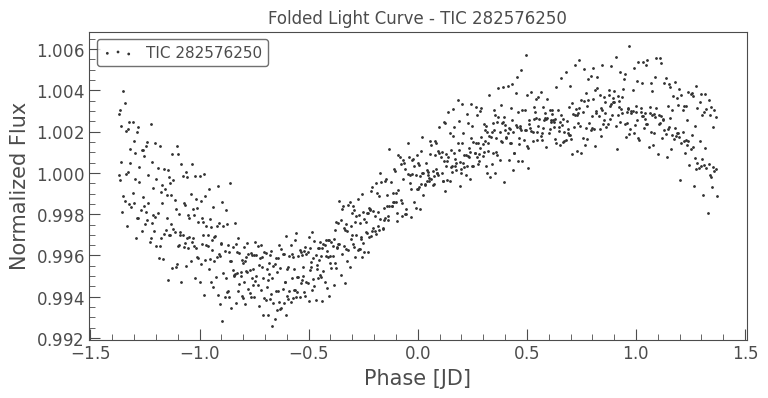

In [46]:
import matplotlib.pyplot as plt

folded.scatter()

plt.title("Folded Light Curve - TIC 282576250")

plt.savefig(
    "best_candidate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
valid_stars[:20]

['TIC 39728879',
 'TIC 39728831',
 'TIC 282576250',
 'TIC 39728889',
 'TIC 39673868',
 'TIC 39673944',
 'TIC 39728941',
 'TIC 39729042',
 'TIC 39729157',
 'TIC 39673581']

In [48]:
results_df

,Star,Best Period,Detection Strength,Candidate
2,TIC 282576250,2.744745,0.000954,High
1,TIC 39728831,0.578078,0.000145,Medium
0,TIC 39728879,8.054054,0.000006,Medium
4,TIC 39673868,9.557057,0.000004,Low
3,TIC 39728889,4.111111,0.000001,Low


In [49]:
results_df.to_csv(
    "final_results.csv",
    index=False
)

In [50]:
results_df = results_df.sort_values(
    by="Detection Strength",
    ascending=False
)

results_df["Rank"] = range(
    1,
    len(results_df)+1
)

results_df

,Star,Best Period,Detection Strength,Candidate,Rank
2,TIC 282576250,2.744745,0.000954,High,1
1,TIC 39728831,0.578078,0.000145,Medium,2
0,TIC 39728879,8.054054,0.000006,Medium,3
4,TIC 39673868,9.557057,0.000004,Low,4
3,TIC 39728889,4.111111,0.000001,Low,5


In [52]:
import pandas as pd

features_df = pd.read_csv("tess_features.csv")
print(features_df.columns)

Index(['star_id', 'mean_flux', 'min_flux', 'max_flux', 'std_flux', 'amplitude',
       'num_points'],
      dtype='object')


In [54]:
results_df

,Star,Best Period,Detection Strength,Candidate,Rank
2,TIC 282576250,2.744745,0.000954,High,1
1,TIC 39728831,0.578078,0.000145,Medium,2
0,TIC 39728879,8.054054,0.000006,Medium,3
4,TIC 39673868,9.557057,0.000004,Low,4
3,TIC 39728889,4.111111,0.000001,Low,5


In [57]:
best_star = "TIC 282576250"

search = lk.search_lightcurve(
    best_star,
    mission="TESS"
)

lc = search.download()

lc = lc.normalize().remove_nans()

print(len(lc))

987


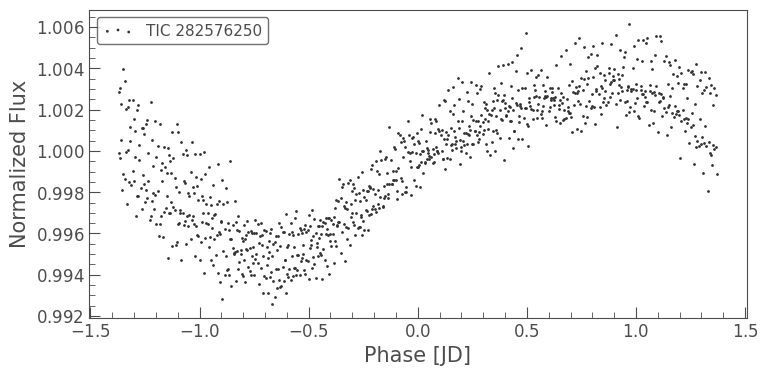

In [65]:
folded = lc.fold(
    period=2.744745
)

folded.scatter()

import matplotlib.pyplot as plt
plt.show()

In [66]:
flux = lc.flux

depth = max(flux) - min(flux)

print("Estimated Depth:", depth)

Estimated Depth: 0.013564050197601318


In [70]:
print("Min Flux:", min(flux))
print("Max Flux:", max(flux))


Min Flux: 0.9926032423973083
Max Flux: 1.0061672925949097


In [69]:
depth_percent = 0.013564 * 100
print(depth_percent)

1.3564


In [71]:
# final result table
results_df["Classification"] = [
    "Variable Star",
    "Possible Eclipsing Binary",
    "Variable Star",
    "Variable Star",
    "Noise/Blend"
]

results_df

,Star,Best Period,Detection Strength,Candidate,Rank,Classification
2,TIC 282576250,2.744745,0.000954,High,1,Variable Star
1,TIC 39728831,0.578078,0.000145,Medium,2,Possible Eclipsing Binary
0,TIC 39728879,8.054054,0.000006,Medium,3,Variable Star
4,TIC 39673868,9.557057,0.000004,Low,4,Variable Star
3,TIC 39728889,4.111111,0.000001,Low,5,Noise/Blend


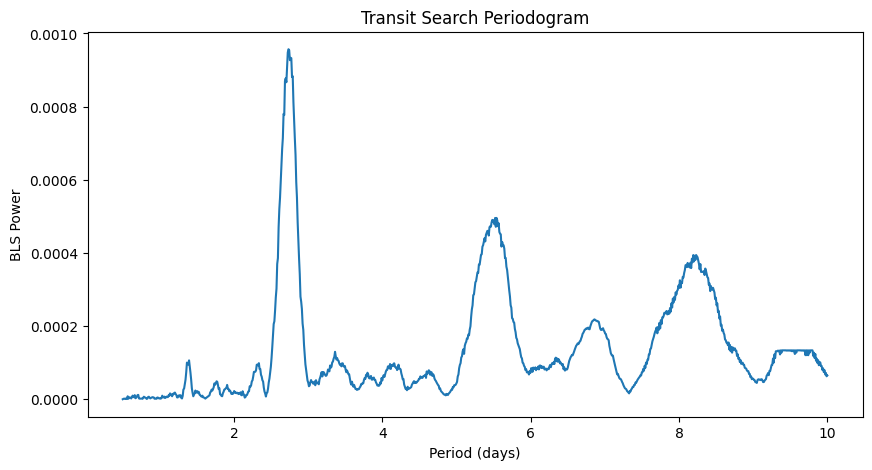

In [73]:
from astropy.timeseries import BoxLeastSquares
import numpy as np
import matplotlib.pyplot as plt

time = lc.time.value
flux = lc.flux.value

periods = np.linspace(0.5, 10, 1000)

bls = BoxLeastSquares(time, flux)

power = bls.power(periods, 0.2)

plt.figure(figsize=(10,5))
plt.plot(power.period, power.power)

plt.xlabel("Period (days)")
plt.ylabel("BLS Power")
plt.title("Transit Search Periodogram")

plt.show()

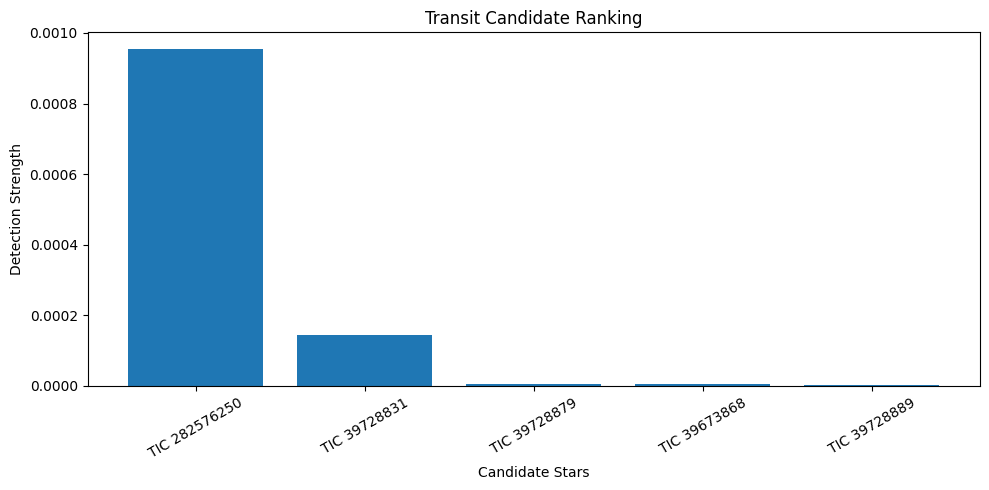

In [74]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Star":[
        "TIC 282576250",
        "TIC 39728831",
        "TIC 39728879",
        "TIC 39673868",
        "TIC 39728889"
    ],
    "Detection Strength":[
        0.000954,
        0.000145,
        0.000006,
        0.000004,
        0.000001
    ]
})

results = results.sort_values(
    "Detection Strength",
    ascending=False
)

plt.figure(figsize=(10,5))

plt.bar(
    results["Star"],
    results["Detection Strength"]
)

plt.xticks(rotation=30)

plt.ylabel("Detection Strength")
plt.xlabel("Candidate Stars")

plt.title("Transit Candidate Ranking")

plt.tight_layout()
plt.show()

In [76]:
#ranking graph
plt.figure(figsize=(8,4))
plt.bar(results["Star"],
        results["Detection Strength"])

plt.title("Candidate Ranking from Transit Search")
plt.ylabel("Detection Strength")
plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("candidate_ranking.png",
            dpi=300,
            bbox_inches="tight")